# Case B · House-price regression

## CRISP-DM question

Can a model estimate residential prices closely enough to support a first-pass
budget screen?

**Learning objective:** establish a linear baseline, compare it with a random
forest, and explain why a more complex model does not automatically improve
out-of-sample error.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from tutorial.data import write_datasets

paths = write_datasets(ROOT / "data")
ROOT

WindowsPath('C:/Users/Xie Yulong/Documents/ChatGPT/面试/data-science-crisp-dm-tutorial')

In [2]:
df = pd.read_csv(paths["housing"])
df.head()

,living_area_sqm,rooms,building_age,distance_to_centre_km,condition,neighborhood,price_hkd_m
0,114.1,4,20,3.89,Good,New town,6.132
1,73.8,3,31,3.51,Excellent,New town,4.075
2,127.5,4,9,12.71,Good,Harbour,8.949
3,133.2,5,16,5.84,Good,Central,10.902
4,46.5,2,20,0.56,Fair,Harbour,3.898


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
living_area_sqm,900.0,103.920444,29.084014,45.000,83.40000,104.2000,122.52500,200.400
rooms,900.0,3.151111,0.865511,1.000,3.00000,3.0000,4.00000,6.000
building_age,900.0,24.378889,14.681180,0.000,12.00000,24.0000,37.00000,50.000
distance_to_centre_km,900.0,7.374767,4.678613,0.400,3.89000,6.4800,9.74500,28.000
price_hkd_m,900.0,6.560326,2.195964,1.102,4.96475,6.5755,8.08275,14.415


In [4]:
from tutorial.examples import run_housing_example

housing = run_housing_example()

pd.DataFrame({
    "linear regression": housing.linear_metrics,
    "random forest": housing.forest_metrics,
}).T

,mae,rmse,r2
linear regression,0.3089,0.3924,0.9690
random forest,0.4705,0.6223,0.9221


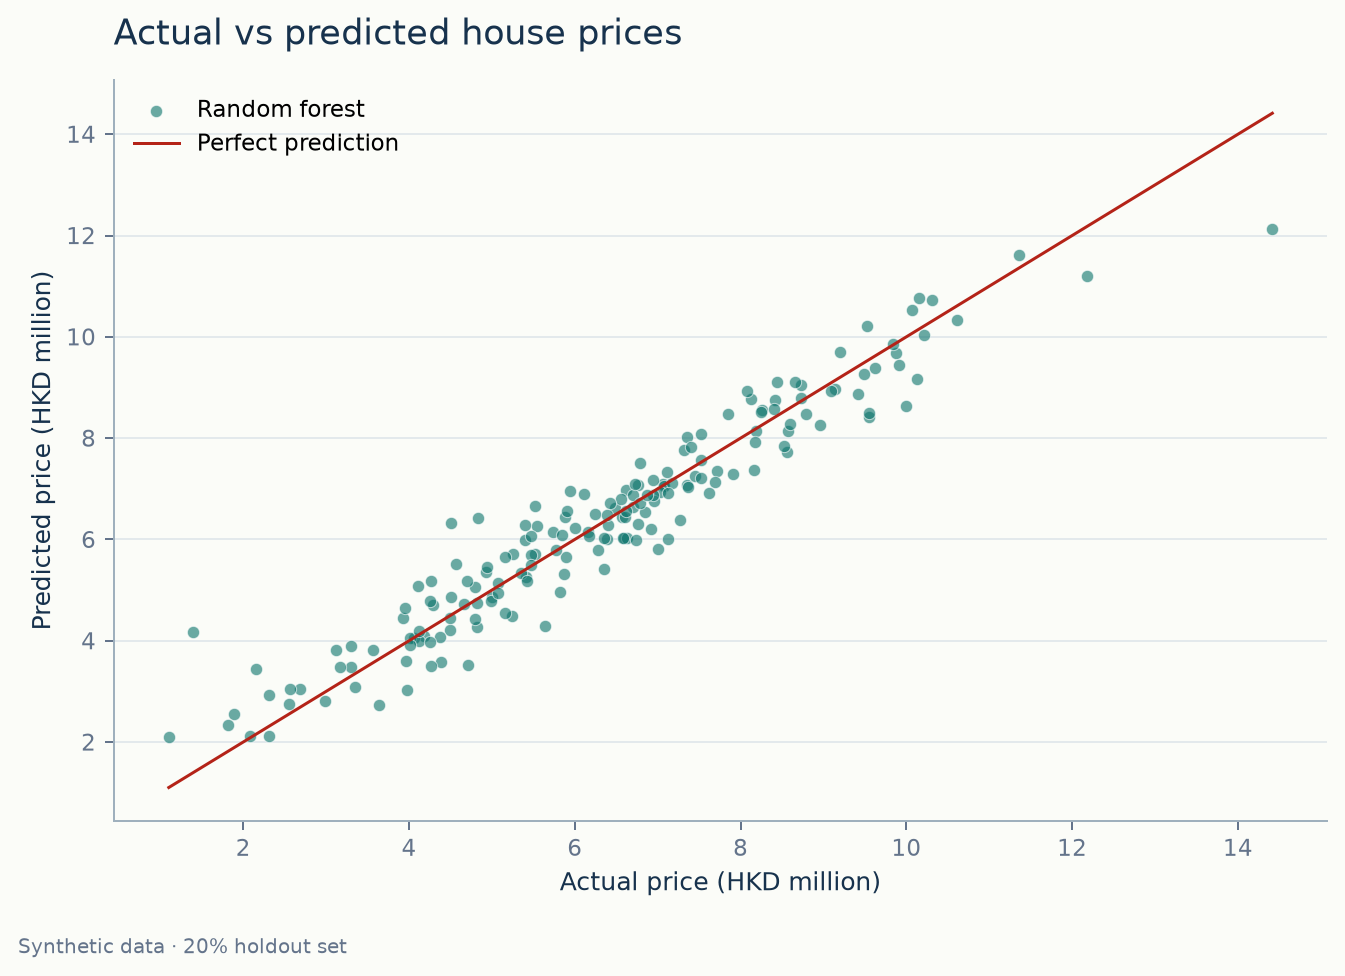

In [5]:
display(Image(filename=str(ROOT / "assets" / "img" / "housing-predictions.png")))

## Interpretation and exercise

The linear baseline has lower MAE and RMSE in this controlled synthetic case.
That is a useful result, not a failed demonstration:

- the data-generating process is close to additive;
- the sample is small;
- default tree settings are not guaranteed to be optimal;
- model complexity must earn its place on the holdout set.

Change one forest hyperparameter and ask whether the improvement is stable or
only a single-split accident.
